# B4 – Performance comparison protocol

**Protocol (fixed before looking at results)**
1. Unit = (bot, vignette). Gold = final Doctor line of the vignette.
2. Labels: *top-1* and *top-3* match to the gold diagnosis, plus *refusal*. First by an LLM judge (different model family from the bots where possible), then **you hand-label a subset** and report Cohen's κ judge vs. you.
3. Metrics per bot: top-1 / top-3 accuracy with 95 % Wilson CI, refusal rate, latency, tokens.
4. Paired comparison (same vignettes for all bots): Cochran's Q (omnibus) and exact McNemar per pair with Holm correction.
5. Report the 5 core vignettes descriptively; use core+extra for inference.

In [1]:
import sys, os, json, time, gc
sys.path.insert(0, "src")
from dotenv import load_dotenv; load_dotenv()
import pandas as pd
pd.set_option("display.max_colwidth", 200); pd.set_option("display.width", 200)
from vignettes import load_vignettes, sample_vignettes
from protocol import run_case, SYSTEM_DOCTOR
import clients, store, metrics

In [2]:
from pathlib import Path

# Move up from `notebook/` to project root once, even if re-run
if Path.cwd().name == "notebooks":
  os.chdir("..")

VIGNETTES = load_vignettes("data/Clinical_Vignettes_26_27.txt")
print(len(VIGNETTES), "clean 4-line vignettes")

117 clean 4-line vignettes


In [3]:
MODE = "single"
JUDGE_SLUG = "openai/gpt-4o-mini"      # pick a judge; note self-preference bias if it is also a tested bot
judge_fn = clients.make_openrouter(JUDGE_SLUG, temperature=0.0, max_tokens=200)

runs = pd.DataFrame(store.load_runs()); runs = runs[runs["mode"] == MODE].drop_duplicates(["bot", "vignette_id"])
gold = {v["id"]: v["gold"] for v in VIGNETTES}
runs["gold"] = runs["vignette_id"].map(gold)

JF = "results/judgements.jsonl"
cache = {}
if os.path.exists(JF):
    for l in open(JF):
        j = json.loads(l); cache[(j["bot"], j["vignette_id"])] = j
for _, r in runs.iterrows():
    k = (r["bot"], r["vignette_id"])
    if k in cache: continue
    j = {"bot": r["bot"], "vignette_id": int(r["vignette_id"]), "judge": JUDGE_SLUG,
         **metrics.judge_answer(judge_fn, r["gold"], r["final_text"])}
    cache[k] = j; open(JF, "a").write(json.dumps(j) + "\n")
J = pd.DataFrame(cache.values()).drop(columns="judge")
df = runs.merge(J, on=["bot", "vignette_id"])
print(df.groupby("bot")[["top1", "top3", "refusal"]].count())

                    top1  top3  refusal
bot                                    
chatgpt               30    30       30
claude                30    30       30
deepseek              30    30       30
gemini                30    30       30
llama2-13b             3     3        3
llama2-13b-ollama      5     5        5
llama2-7b              5     5        5
llama2-7b-ollama       5     5        5
local-qwen2.5-1.5b     5     5        5


## Manual validation of the judge
Export, fill `manual_top1` / `manual_top3` (0/1) for as many rows as you can (all core rows at least), save, and re-run the next cell.

In [10]:
man = pd.read_csv("results/manual_labels.csv")
draft = pd.read_csv("results/manual_labels_core_DRAFT.csv")
MAN = man.drop(columns=["manual_top1", "manual_top3"]).merge(draft, on=["bot", "vignette_id"], how="left")
MAN.to_csv("results/manual_labels.csv", index=False)
MAN.head()

,bot,vignette_id,set,gold,final_text,top1,top3,manual_top1,manual_top3
0,gemini,15,core,It sounds like you might have social anxiety disorder. We can explore treatment options.,Here are the top 3 most likely diagnoses:\n\n1. **Panic Disorder with Agoraphobia:** Recurrent unexpected panic attacks combined with anxiety about being in places or situations from which escape...,0,1,0.0,1.0
1,gemini,40,core,Your symptoms raise concerns about diverticulitis. We'll perform imaging tests.,"Here are the top 3 most likely diagnoses:\n\n1. **Diverticulitis:** Left-sided abdominal pain, changes in bowel movements, and bloating are classic symptoms, especially in older adults.\n2. **Ir...",1,1,1.0,1.0
2,gemini,64,core,Your symptoms may be linked to increased intracranial pressure. We'll order imaging to investigate further.,"Here are the top 3 most likely diagnoses:\n\n1. **Migraine:** Classic presentation with severe headaches, nausea, and morning exacerbation, often triggered by sleep patterns.\n2. **Cluster Headach...",0,0,0.0,0.0
3,gemini,65,core,Your symptoms might be due to an electrolyte imbalance. We'll check your blood levels.,"Here are the top 3 most likely diagnoses:\n\n1. **Electrolyte Imbalance (e.g., hypomagnesemia, hypokalemia, hypocalcemia):** While you mentioned hydration, specific electrolyte deficiencies are a...",1,1,1.0,1.0
4,gemini,82,core,Your symptoms may indicate type 1 diabetes. We'll check your blood sugar levels.,"Here are the top 3 most likely diagnoses:\n\n1. **Type 1 Diabetes Mellitus:** The classic triad of polydipsia (thirst), polyuria (frequent urination), and weight loss, coupled with sugar cravings...",1,1,1.0,1.0


In [11]:
if not os.path.exists(MAN):
    df[["bot", "vignette_id", "set", "gold", "final_text", "top1", "top3"]].assign(manual_top1="", manual_top3="").to_csv(MAN, index=False)
    print("exported", MAN, "-> fill manual_top1/manual_top3, then re-run")
else:
    man = pd.read_csv(MAN)
    for lab in ("top1", "top3"):
        m = man.dropna(subset=[f"manual_{lab}"])
        if len(m):
            k, n = metrics.kappa(m[f"manual_{lab}"], m[lab]); print(f"kappa judge vs manual ({lab}): {k:.2f} (n={n})")
    # manual labels override the judge where available
    ov = man.dropna(subset=["manual_top1"]).set_index(["bot", "vignette_id"])
    for lab in ("top1", "top3"):
        for (b, v), row in ov.iterrows():
            df.loc[(df.bot == b) & (df.vignette_id == v), lab] = int(row[f"manual_{lab}"])

TypeError: stat: path should be string, bytes, os.PathLike or integer, not DataFrame


== core5 / top1 ==
                bot  n  correct  accuracy  ci95_low  ci95_high
          deepseek  5        5       1.0     0.566      1.000
           chatgpt  5        4       0.8     0.376      0.964
            claude  5        4       0.8     0.376      0.964
            gemini  5        3       0.6     0.231      0.882
 llama2-13b-ollama  5        2       0.4     0.118      0.769
  llama2-7b-ollama  5        2       0.4     0.118      0.769
         llama2-7b  5        2       0.4     0.118      0.769
        llama2-13b  3        0       0.0     0.000      0.561
local-qwen2.5-1.5b  5        0       0.0     0.000      0.434

== core5 / top3 ==
                bot  n  correct  accuracy  ci95_low  ci95_high
           chatgpt  5        5     1.000     0.566      1.000
            claude  5        5     1.000     0.566      1.000
          deepseek  5        5     1.000     0.566      1.000
 llama2-13b-ollama  5        5     1.000     0.566      1.000
            gemini  5       

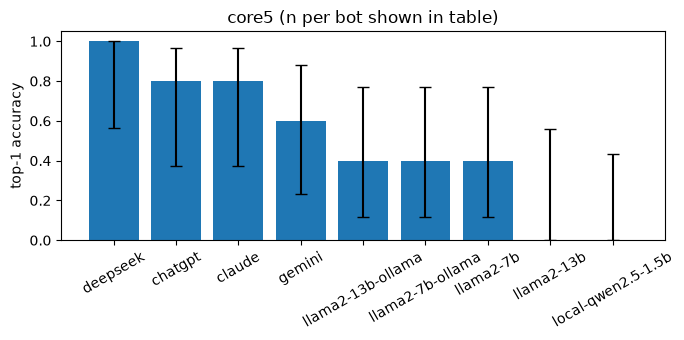

In [5]:
import matplotlib.pyplot as plt
def report(d, tag):
    out = {}
    for lab in ("top1", "top3"):
        t = metrics.accuracy_table(d, lab); out[lab] = t
        t.to_csv(f"results/acc_{tag}_{lab}.csv", index=False); print(f"\n== {tag} / {lab} ==\n", t.round(3).to_string(index=False))
    w = metrics.wide(d, "top1")
    print("\npaired vignettes:", len(w), "| Cochran Q:", metrics.cochran(w))
    pm = metrics.pairwise_mcnemar(w); pm.to_csv(f"results/mcnemar_{tag}.csv", index=False); print(pm.round(4).to_string(index=False))
    eff = metrics.efficiency_table(d); eff.to_csv(f"results/efficiency_{tag}.csv", index=False); print("\n", eff.to_string(index=False))
    t = out["top1"]
    plt.figure(figsize=(7, 3.5))
    plt.bar(t["bot"], t["accuracy"], yerr=[t["accuracy"] - t["ci95_low"], t["ci95_high"] - t["accuracy"]], capsize=4)
    plt.ylabel("top-1 accuracy"); plt.ylim(0, 1.05); plt.title(f"{tag} (n per bot shown in table)"); plt.xticks(rotation=30)
    plt.tight_layout(); plt.savefig(f"results/acc_{tag}.png", dpi=150); plt.show()

report(df[df["set"] == "core"], "core5")

**All vignettes (core + extra).** Only bots that answered every vignette are compared, so the data stay paired.

excluded from inference (incomplete coverage): ['llama2-7b-ollama', 'local-qwen2.5-1.5b', 'llama2-13b', 'llama2-7b', 'llama2-13b-ollama']

== all / top1 ==
      bot  n  correct  accuracy  ci95_low  ci95_high
deepseek 30       26     0.867     0.703      0.947
 chatgpt 30       24     0.800     0.627      0.905
  claude 30       24     0.800     0.627      0.905
  gemini 30       20     0.667     0.488      0.808

== all / top3 ==
      bot  n  correct  accuracy  ci95_low  ci95_high
deepseek 30       29     0.967     0.833      0.994
 chatgpt 30       28     0.933     0.787      0.982
  claude 30       27     0.900     0.744      0.965
  gemini 30       27     0.900     0.744      0.965

paired vignettes: 30 | Cochran Q: {'Q': 6.0, 'df': 3, 'p': 0.11161022509471268}
       A        B  A_only_correct  B_only_correct  p_raw  p_holm
 chatgpt   claude               3               3 1.0000  1.0000
 chatgpt deepseek               1               3 0.6250  1.0000
 chatgpt   gemini           

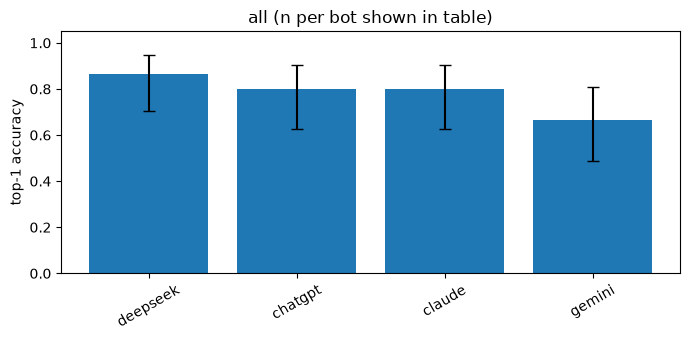

In [6]:
ids_all = set(df.vignette_id)
cover = df.groupby("bot")["vignette_id"].nunique()
bots_full = cover[cover == len(ids_all)].index
print("excluded from inference (incomplete coverage):", list(set(cover.index) - set(bots_full)))
report(df[df["bot"].isin(bots_full)], "all")